In [15]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [16]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [17]:
prefix = '/mnt/staging/' 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"
figure_config_root = str(PREPARES / "config") + "/"


mouse='cm125'

In [18]:
load_path = str(PREPARES / "heterogeneity/all-seed") + "/"
load_contour_path = str(PREPARES / "heterogeneity-contours") + "/"

bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV']
mice_list = ['cm125','cm193','cm229','cm216','cm126','cm128']
corr_maps_dict={}; sensory_ind_dict={};node_coords_dict={};
clean_contours_M2_dict={};M2_homunculus_dict={};
clean_contours_S1_dict={};S1_homunculus_dict={};
clean_contours_fit={};clean_contours_S1_dict={};M2_homunculus_fit={}
mask_dict = {}; masked_brain_dict = {}
threshold_S1_dict = {}; threshold_M2_dict = {};
for mouse in mice_list:
    corr_maps_dict[mouse]={}
    clean_contours_M2_dict[mouse] = load_pickle(load_contour_path+'clean_contours_'+mouse)
    M2_homunculus_dict[mouse] = load_pickle(load_contour_path+'dict_M2_full_'+mouse)

    clean_contours_fit[mouse] = load_pickle(load_contour_path+'clean_contours_fit_'+mouse)
    M2_homunculus_fit[mouse] = load_pickle(load_contour_path+'dict_fit_result_M2_'+mouse)
    
    clean_contours_S1_dict[mouse] = load_pickle(load_contour_path+'clean_contours_S1_'+mouse)
    S1_homunculus_dict[mouse] = load_pickle(load_contour_path+'dict_S1_full_'+mouse)

    dict_save = load_pickle(load_contour_path+'dict_save_'+mouse)
    sensory_ind = dict_save['sensory_ind']
    sensory_ind_dict[mouse] = sensory_ind
    threshold_S1_dict[mouse] = dict_save['dict_threshold_S1']
    threshold_M2_dict[mouse] = dict_save['dict_threshold_M2']

    with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:
        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)
        
        mask = IDX_sorted >0
        mask = mask.astype(float)
        mask[mask==0]='nan'
        
        masked_brain=np.nan_to_num(mask,nan=67000)
        # plt.figure()
        # plt.imshow(masked_brain,cmap='gray',vmin=40000,vmax=70000)
        masked_brain_dict[mouse] = masked_brain
        
    node_coords_dict[mouse] = node_coords
    mask_dict[mouse]=mask


# lime_caxis_dict['cm126']=np.arange(10,4200)
# lime_caxis_dict['cm128']=np.arange(10,5500)
# lime_caxis_dict['cm229']=np.arange(10,2700)
# lime_caxis_dict['cm193']=np.arange(10,4200) 
# lime_caxis_dict['cm284']=np.arange(10,3000) 

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_33086/1764104255.py:34: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


In [19]:
df_threshold_S1 = pd.DataFrame.from_dict(threshold_S1_dict, orient='index')[bdp_w_order].loc[mice_list]
df_threshold_M2 = pd.DataFrame.from_dict(threshold_M2_dict, orient='index')[bdp_w_order].loc[mice_list]


In [20]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# palatte_dict['LT'] = '#b3b3b3'
# palatte_dict['RT']  = '#e4c494' ##b69d76 back up
palatte_dict['RW'] = '#6932a5'

In [21]:
bdp_w_order = ['LHP','RHP','LFP','RFP','LM','RM','LW','RW','LN','RN','LV','RV']

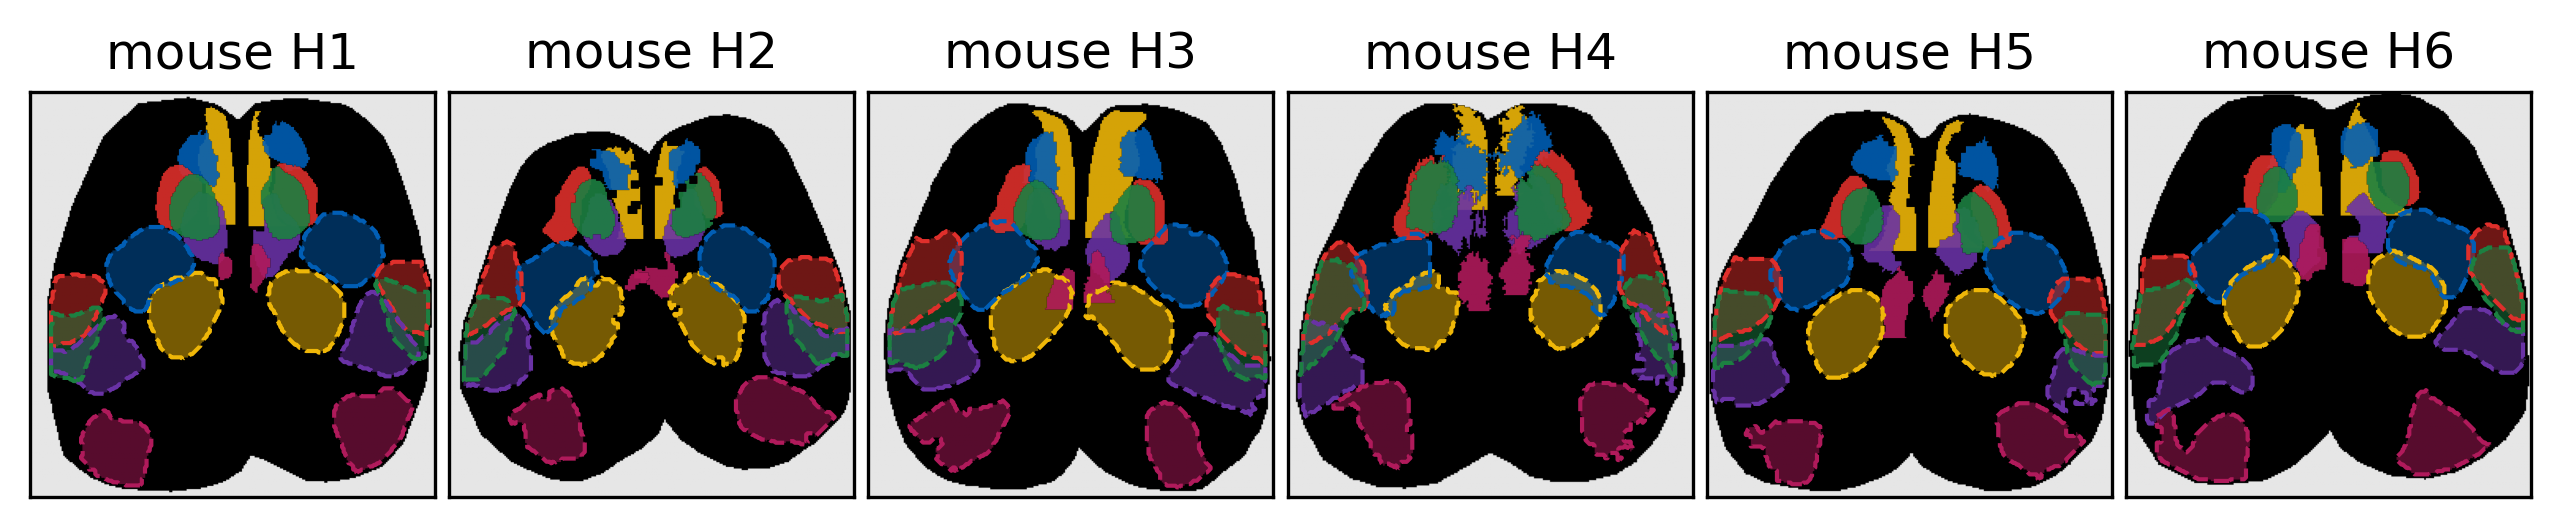

In [22]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

x_start = x_offset
for i_ax in range(len(mice_list)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+6,x_start:x_start+6])".format(i_ax))
    x_start = x_start+6+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    
    
for i_ax,mouse in enumerate(mice_list):

#     clean_contours_M2_dict[mouse] = load_pickle(load_contour_path+'clean_contours_'+mouse)
#     clean_contours_fit[mouse] = load_pickle(load_contour_path+'clean_contours_fit_'+mouse) 
#     clean_contours_S1_dict[mouse] = load_pickle(load_contour_path+'clean_contours_S1_'+mouse)
    
    exec("ax{}.imshow(masked_brain_dict[mouse],cmap='gray',vmin=40000,vmax=70000)".format(i_ax))
    
    if mouse =='cm229':
        exec("ax{}.set_xlim([12,256]);ax{}.set_ylim([256,12]);".format(i_ax,i_ax))
    if mouse =='cm216':
        exec("ax{}.set_xlim([24,252]);ax{}.set_ylim([228,0]);".format(i_ax,i_ax))
    if mouse =='cm126':
        exec("ax{}.set_xlim([9,256]);ax{}.set_ylim([256,9]);".format(i_ax,i_ax))
    if mouse =='cm128':
        exec("ax{}.set_xlim([9,256]);ax{}.set_ylim([247,0]);".format(i_ax,i_ax))
            
    for i_bdp ,bdp in enumerate(bdp_w_order):
        # if bdp in ['LHP','RHP']:
        #     contour = clean_contours_fit[mouse][bdp][0]
        # else:
        contour = clean_contours_M2_dict[mouse][bdp][0]
            
        bodypart_name_here=bdp.replace('L','R')
        # ===================
        r_mask = contour_to_roi(np.ones((256,256)),contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.9)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.8)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.6)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)

        exec("ax{}.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb)".format(i_ax))

        S1_contour = clean_contours_S1_dict[mouse][bdp][0]
        r_mask = contour_to_roi(np.ones((256,256)),S1_contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.5)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.4)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_here],alpha = 0.3)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        exec("ax{}.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb)".format(i_ax))
        exec("ax{}.plot(S1_contour[:,1],S1_contour[:,0],linewidth=1,linestyle='dashed',color=palatte_dict[bodypart_name_here],alpha=1)".format(i_ax))
    exec("ax{}.set_title('mouse H{}')".format(i_ax,i_ax+1))

plt.savefig('fig3-M2-S1-topography-heterogeneity-multiple-mice.svg',format='svg',dpi=300)

# STATS

In [23]:
df_S1_long = df_threshold_S1.reset_index().melt(id_vars='index', var_name='BDP', value_name='Threshold')
df_S1_long['Region'] = 'S1'

df_M2_long = df_threshold_M2.reset_index().melt(id_vars='index', var_name='BDP', value_name='Threshold')
df_M2_long['Region'] = 'M2'

df_all = pd.concat([df_S1_long, df_M2_long], ignore_index=True)
df_all.rename(columns={'index': 'Mouse'}, inplace=True)


In [24]:
palette_dict_filtered = {k: palatte_dict[k] for k in df_S1_long['BDP'].unique() if k in palatte_dict}


/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_33086/79557246.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_33086/79557246.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


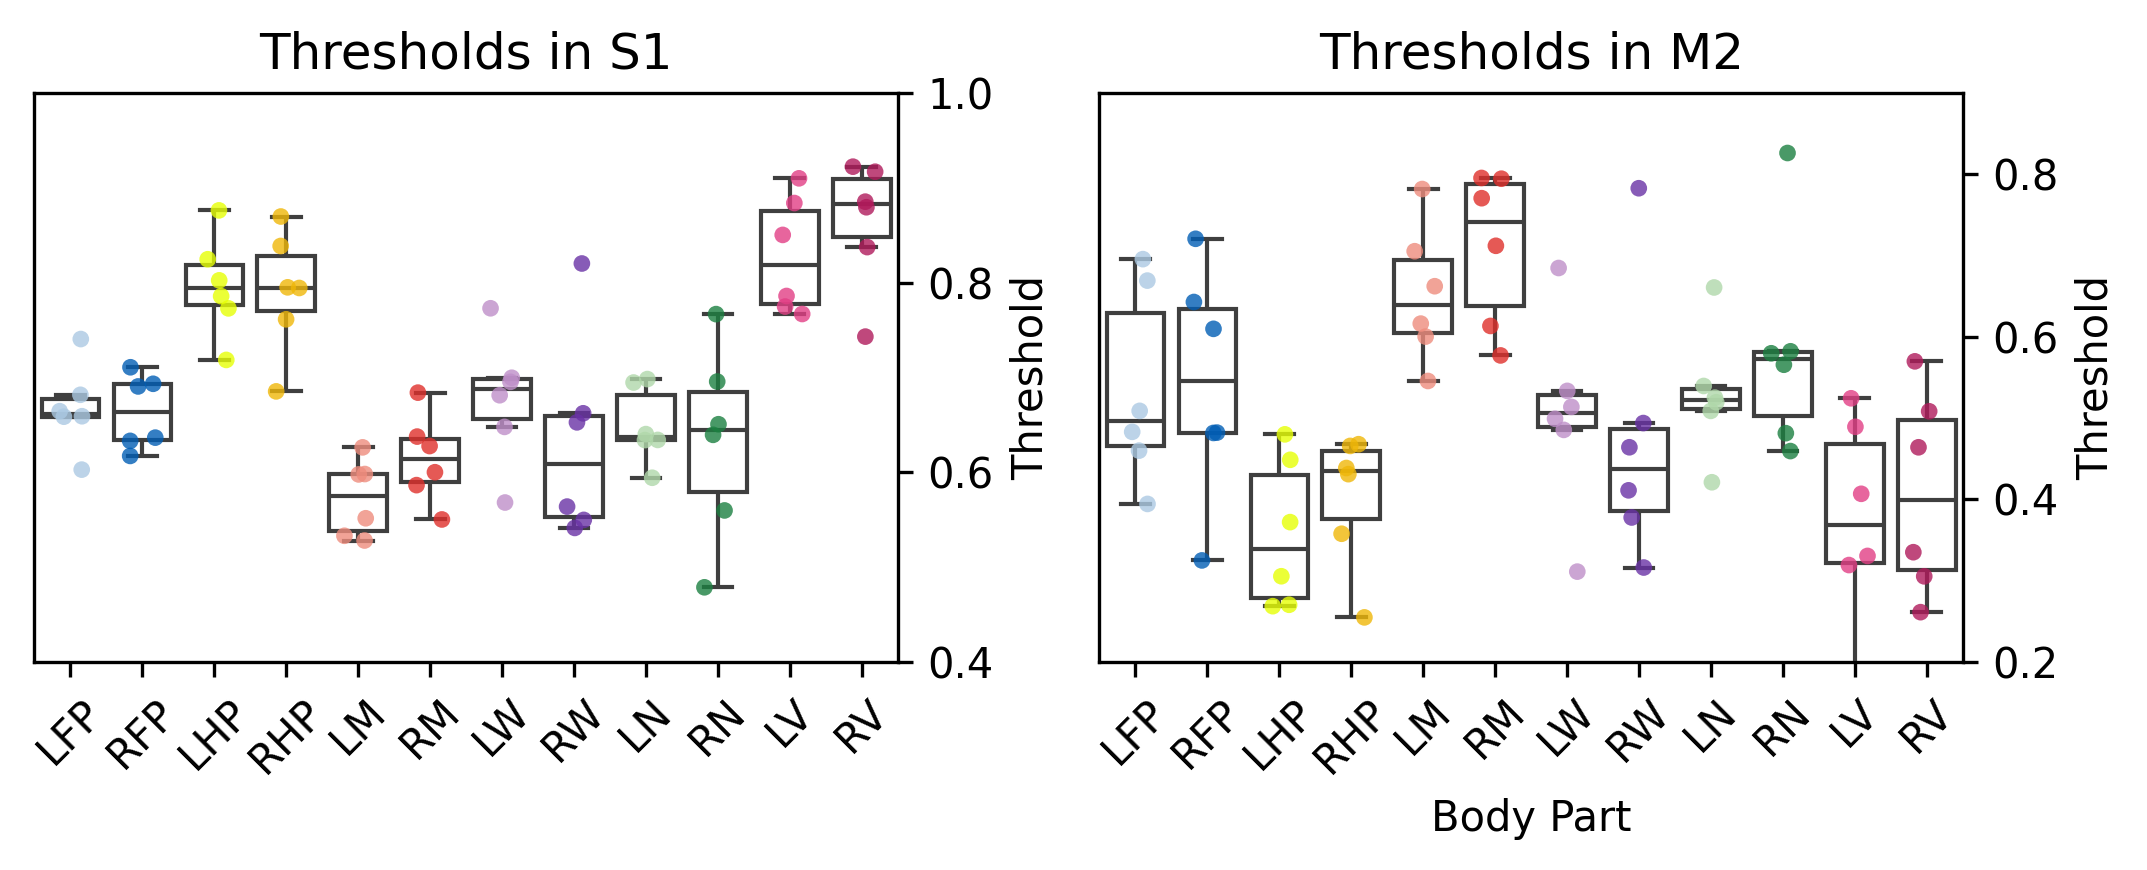

In [25]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.25, 3), sharex=True, dpi=300)

# ---- S1 ----
sns.boxplot(
    data=df_S1_long,
    x='BDP',
    y='Threshold',
    ax=ax1,
    showcaps=True,
    boxprops={'facecolor':'none'},  # make box face transparent
    showfliers=False,
    linewidth=1,
)

# Add jitter points with color by BDP
sns.stripplot(
    data=df_S1_long,
    x='BDP',
    y='Threshold',
    ax=ax1,
    palette=palette_dict_filtered,
    size=4,
    jitter=0.2,
    alpha=0.8
)

ax1.set_title('Thresholds in S1')
ax1.set_ylabel('Threshold')
ax1.set_xlabel('')
ax1.tick_params(axis='x', rotation=45)

# ---- M2 ----
sns.boxplot(
    data=df_M2_long,
    x='BDP',
    y='Threshold',
    ax=ax2,
    showcaps=True,
    boxprops={'facecolor':'none'},
    showfliers=False,
    linewidth=1,
)

sns.stripplot(
    data=df_M2_long,
    x='BDP',
    y='Threshold',
    ax=ax2,
    palette=palette_dict_filtered,
    size=4,
    jitter=0.2,
    alpha=0.8
)

ax2.set_title('Thresholds in M2')
ax2.set_ylabel('Threshold')
ax2.set_xlabel('Body Part')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
ax1.set_ylim(0.405, 1) 
ax1.set_yticks([0.4,0.6,0.8,1])
ax2.set_ylim(0.2, 0.9) 
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")

# plt.savefig('fig3-STATS-multiple-mice.svg',format='svg',dpi=300)

# S1-M2 correlation distribution

In [26]:
load_path = str(PREPARES / "heterogeneity") + "/"
results = load_pickle(load_path+'correlation_distribution')

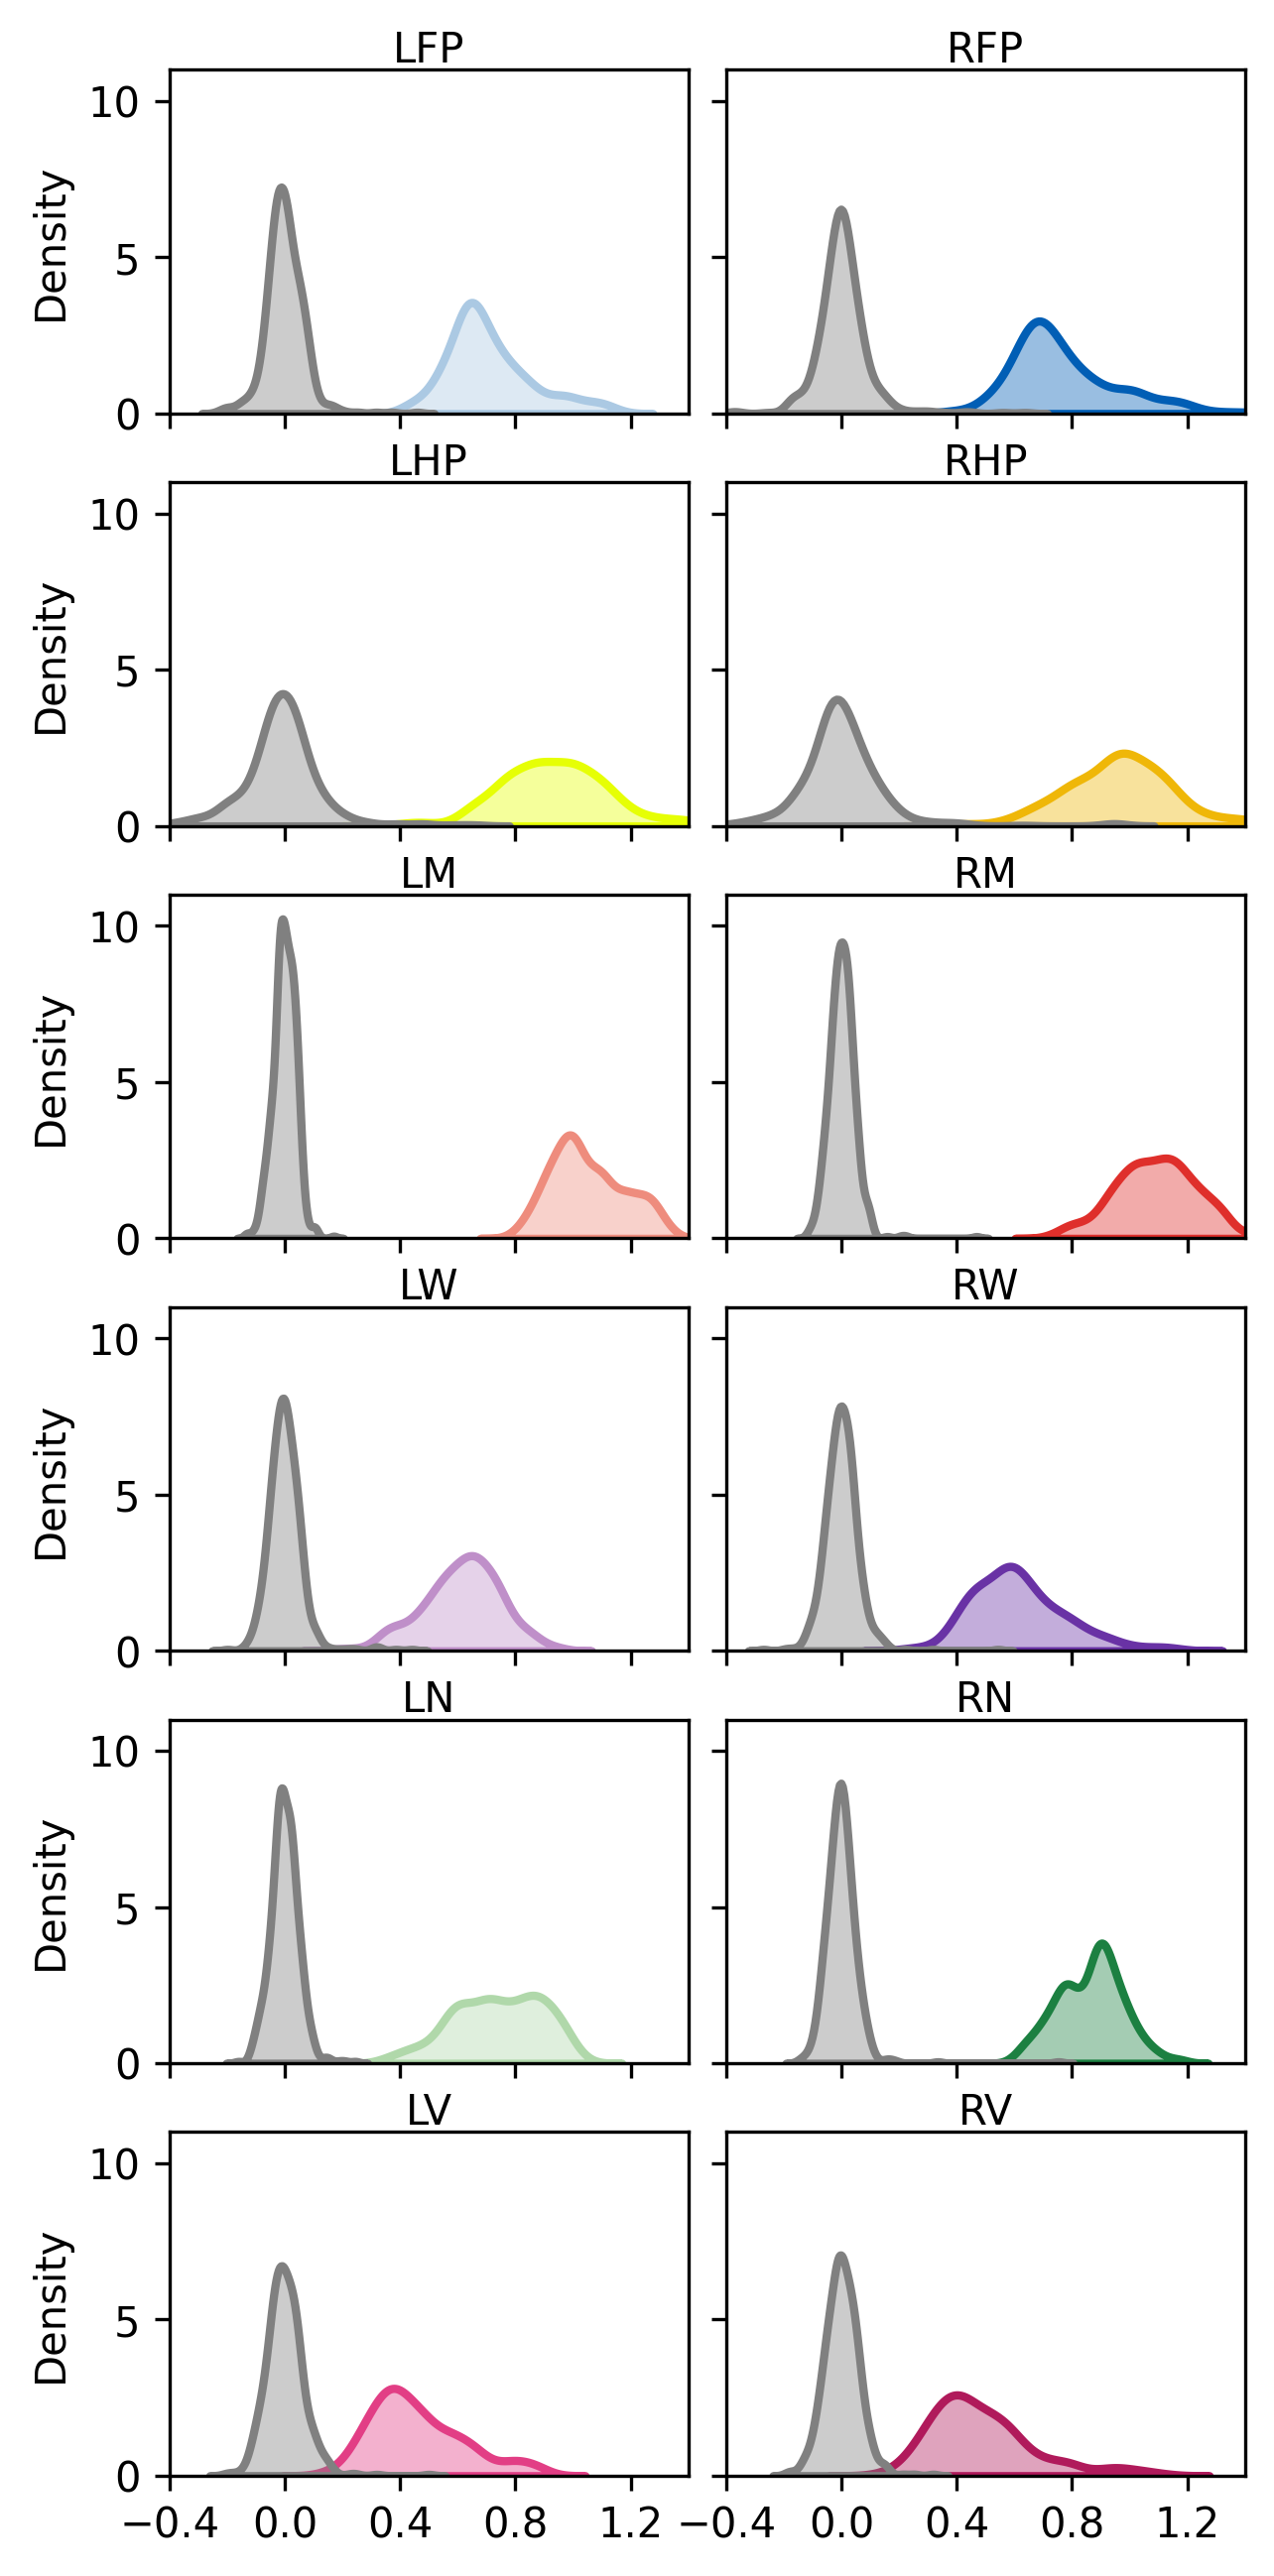

In [27]:
from matplotlib import colors
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=6

y_start = y_offset
y_stop = y_start+5
for i_ax in range(int(len(bdp_w_order)/2)):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_offset:x_offset+8])".format(i_ax))
    y_start = y_stop+1
    y_stop = y_start+5

y_start = y_offset
y_stop = y_start+5
for i_ax in range(int(len(bdp_w_order)/2),len(bdp_w_order)):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_offset+8:x_offset+8+8])".format(i_ax))
    y_start = y_stop+1
    y_stop = y_start+5

    

bdp_w_order_L = ['LFP','LHP','LM','LW','LN','LV']
bdp_w_order_R = ['RFP','RHP','RM','RW','RN','RV']
bdp_w_order = bdp_w_order_L + bdp_w_order_R


for i_ax, body in enumerate(bdp_w_order):
    ax = eval(f"ax{i_ax}")
    
    sns.kdeplot(
        results[body]['original'],
        fill=True,
        label='Original',
        color=palatte_dict[body],
        alpha=0.4,
        linewidth=2,
        ax=ax
    )
    
    sns.kdeplot(
        results[body]['shuffled'],
        fill=True,
        label='Shuffled',
        color='gray',
        alpha=0.4,
        linewidth=2,
        ax=ax
    )
    
    ax.set_title(f"{body}", fontsize=10,y=0.95)
    ax.set_xlim([-0.4, 1.4])
    ax.set_ylim([0, 11])
    ax.set_xticks([-0.4, 0,0.4,0.8,1.2] )
    ax.set_yticks([ 0,5,10] )
    
for i_ax in range(12):
    
    if i_ax in [5,11]:
        a=1
    else:
        exec("ax{}.set_xticklabels([])".format(i_ax))   
    if i_ax>5:
        exec("ax{}.set_yticklabels([])".format(i_ax))
        exec("ax{}.set_ylabel('')".format(i_ax))
plt.subplots_adjust(wspace=1.2,hspace=-0.0)
plt.savefig('figS3-STATS-corr-distribution.svg',format='svg',dpi=300)